# Module 5 - Detection and Attribution (DAMIP)

In this exercise, you will be working with data from the CMIP6 Detection and Attribution Model Intercomparison Project (DAMIP) archive, and investigating the contributions to warming from natural forcings, aerosols, and anthropogenic greenhouse gases. You will also have an opportunity to work with the HadCRUT5 temperature data, and using simple techniques, separate the warming trend from internal variability.

### Required Files

+ temperature-anomaly-HadCRUT5-preindustrial.csv
+ CMIP6_historical_tas.nc
+ CMIP6_DAMIP_hist-nat_tas.nc
+ CMIP6_DAMIP_hist-GHG_tas.nc
+ CMIP6_DAMIP_hist-aer_tas.nc

## Detection of Climate Change in the HadCRUT5 dataset

Here, we will be working with the globally averaged annual mean temperature anomaly data from the HadCRUT5 (combined land and ocean) historical temperature record. Let's start by taking a look at the global mean temperature anomalies (relative to 1861–1890, taken to be the preindustrial period): 

In [1]:
### Load Packages ###
from matplotlib import pyplot as plt
import xarray as xr
import numpy as np
import dask
import seaborn as sns
import pandas as pd

## Read in HadCRUT5 Anomaly Data ##
hadcrut5_fil = 'temperature-anomaly-HadCRUT5-preindustrial.csv'
hadcrut5_df = pd.read_csv(hadcrut5_fil) #read into Pandas Dataframe

## Select only the global mean average temperature ##
hadcrut5_globmean_df = hadcrut5_df[hadcrut5_df['Entity'] == 'World'] #select only global anomalies
hadcrut5_globmean_df = hadcrut5_globmean_df[['Year','Average']] #select only the average temperature
print(hadcrut5_globmean_df)


     Year   Average
354  1850 -0.062523
355  1851  0.100442
356  1852  0.139907
357  1853  0.101611
358  1854  0.070376
..    ...       ...
526  2022  1.165803
527  2023  1.473764
528  2024  1.532965
529  2025  1.411990
530  2026  1.406081

[177 rows x 2 columns]


## Calculating A Trend (Detection)

Detection of a change is often done by looking at trends over the historical period. Let's calculate the global mean temperature trend for the HadCRUT5 data over the historical period, as well as over the satellite era (usually taken to be from 1980 onwards), and plot the resulting timeseries and trends. We will be making use of Scipy's linear regression package for this. Show the trends as a decadal temperature change. How do the trends differ over the historical period, and the satellite era?

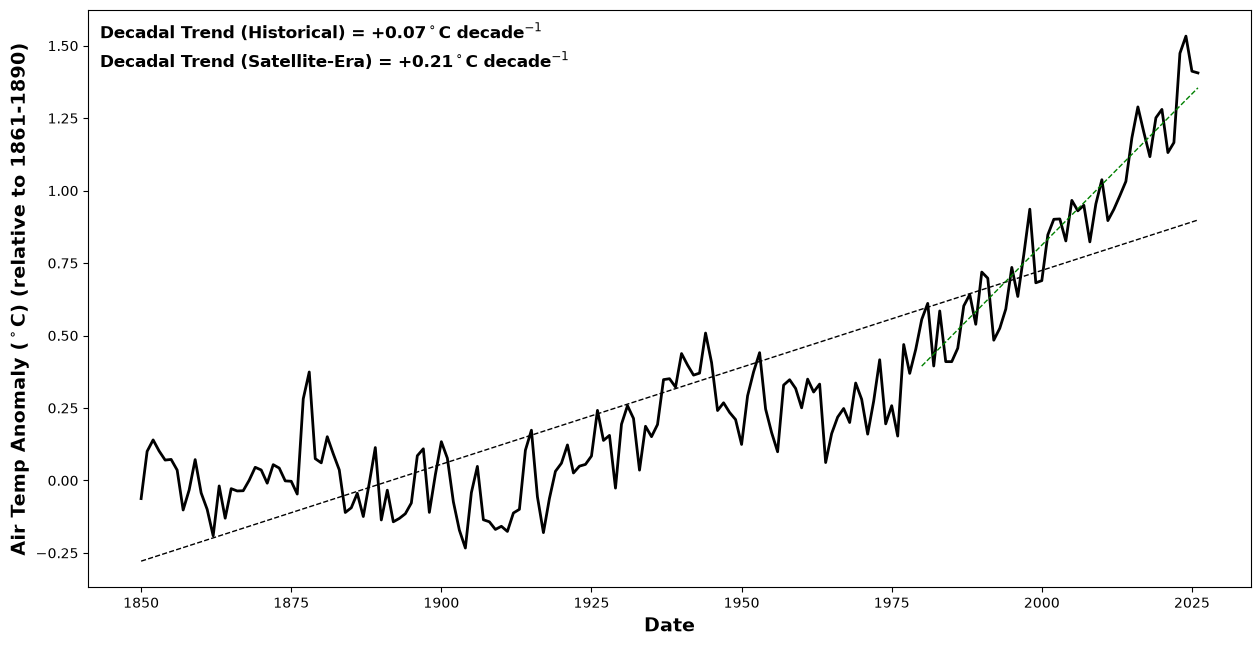

In [2]:
### Load Packages ###
from scipy import stats


### Calculate Trends ###

## 1850 - Present ##
years = hadcrut5_globmean_df['Year'].values
temps = hadcrut5_globmean_df['Average'].values

slope_hist, intercept_hist, r, p, std_err = stats.linregress(years,temps) #grab the slope and intercept from a linear regression of year and global mean temperature
predicted_temps_hist = slope_hist*years + intercept_hist #calculate the predicted temperatures to plot as a trendline

decadal_trend_hist = slope_hist*10
decadal_trend_hist = np.round(decadal_trend_hist,2) #round to 2 decimal places

## Satellite Era ###
hadcrut5_sat_era_df = hadcrut5_globmean_df[hadcrut5_globmean_df['Year'] >= 1980] #only select data from 1980 onwards

years_sat_era = hadcrut5_sat_era_df['Year'].values
temps_sat_era = hadcrut5_sat_era_df['Average'].values

slope_sat_era, intercept_sat_era, r, p, std_err = stats.linregress(years_sat_era,temps_sat_era) #grab the slope and intercept from a linear regression of year and global mean temperature
predicted_temps_sat_era = slope_sat_era*years_sat_era + intercept_sat_era #calculate the predicted temperatures over satellite era

decadal_trend_sat = slope_sat_era*10
decadal_trend_sat = np.round(decadal_trend_sat,2) #round to 2 decimal places

### Create Plot ###
fig,ax = plt.subplots(figsize=(15,7.5))
ax.plot(years,temps,color='black',linewidth=2) #plot of global mean tempreature timeseries
ax.plot(years,predicted_temps_hist,color='black',linewidth=1,linestyle='dashed') #trendline over historical era
ax.plot(years_sat_era,predicted_temps_sat_era,color='green',linewidth=1,linestyle='dashed') #trendline over historical era
ax.set_ylabel('Air Temp Anomaly ($^\\circ$C) (relative to 1861-1890)',fontsize=14,fontweight='bold')
ax.set_xlabel('Date',fontsize=14,fontweight='bold')
ax.text(0.01,0.95,'Decadal Trend (Historical) = +'+str(decadal_trend_hist)+'$^\\circ$C decade$^{-1}$',transform=ax.transAxes,fontsize=12,fontweight='bold') #include decadal temperature change over historical period
ax.text(0.01,0.90,'Decadal Trend (Satellite-Era) = +'+str(decadal_trend_sat)+'$^\\circ$C decade$^{-1}$',transform=ax.transAxes,fontsize=12,fontweight='bold') #include decadal temperature change over satellite era
plt.show()

## Comparing the DAMIP runs to the HadCRUT5 observations (Attribution)

In the previous we detected a change in the global mean temperature. We will now look into attributing the cause of the climate changes, using data from the CMIP6 Detection and Attribution Model Intercomparison Project (DAMIP) archive, which represent counter-factual scenarios where temperatures only respond to a subset of forcings. We will be investigating the contributions to warming from natural forcings (hist-nat), aerosols (hist-aer), and anthropogenic greenhouse gases (hist-GHG). 

To do so, we are going to import global mean temperatures from each of the DAMIP scenarios, along with data from the CMIP6 historical scenario (with all forcings) and do some pre-processing of the data. Next you'll calculate the temperature anomalies (relative to 1861-1890) for each of the model and scenario combinations, before plotting the anomalies alongside the HadCRUT5 observations between 1850-2014:

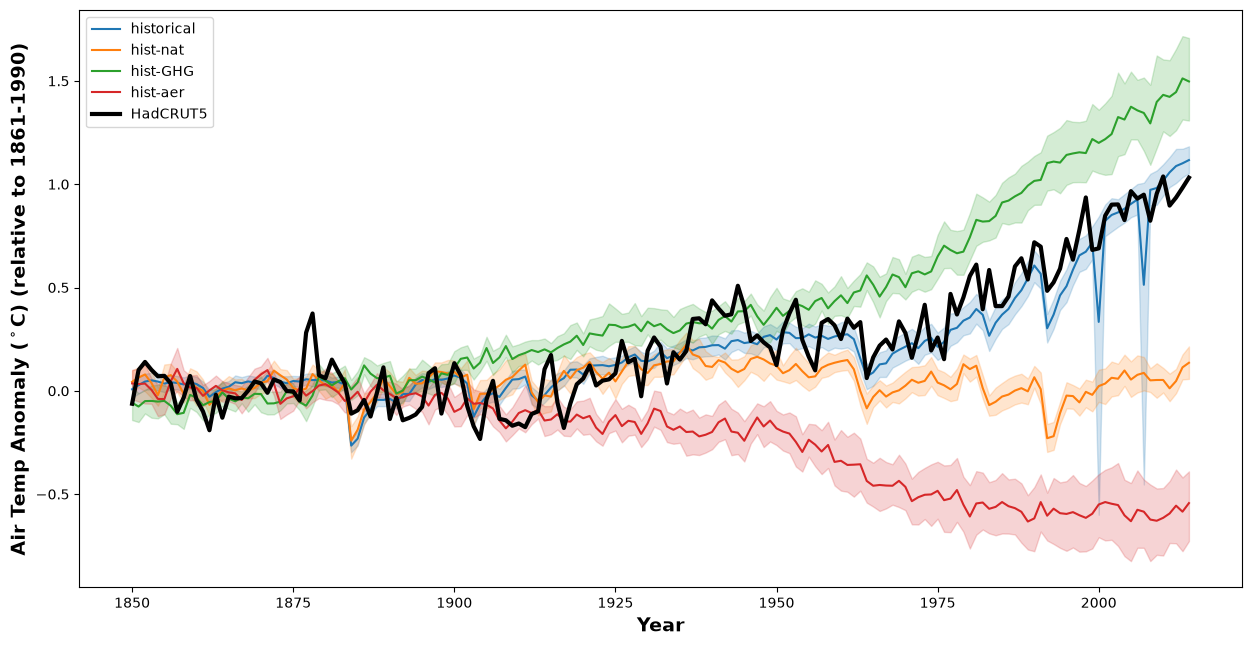

In [3]:
### Grab data from DAMIP and historical scenarios ###

hist_fil = 'CMIP6_historical_tas.nc' #historical scenario file
hist_ds = xr.open_dataset(hist_fil)

histnat_fil = 'CMIP6_DAMIP_hist-nat_tas.nc' #hist-nat (natural forcings only) DAMIP scenario file
histnat_ds = xr.open_dataset(histnat_fil)

histGHG_fil = 'CMIP6_DAMIP_hist-GHG_tas.nc' #hist-GHG (anthropogenic GHG forcings only) DAMIP scenario file
histGHG_ds = xr.open_dataset(histGHG_fil)

histaer_fil = 'CMIP6_DAMIP_hist-aer_tas.nc' #hist-aer DAMIP scenario file
histaer_ds = xr.open_dataset(histaer_fil)


### Convert to Pandas Dataframe ###

hist_df = hist_ds.to_dataframe().reset_index().dropna(axis="index",subset=['tas']) #drop missing values (since not all years are included for all models)
hist_df['scenario'] = 'historical'
histnat_df = histnat_ds.to_dataframe().reset_index().dropna(axis="index",subset=['tas']) #drop missing values (since not all years are included for all models)
histnat_df['scenario'] = 'hist-nat'
histGHG_df = histGHG_ds.to_dataframe().reset_index().dropna(axis="index",subset=['tas']) #drop missing values (since not all years are included for all models)
histGHG_df['scenario'] = 'hist-GHG'
histaer_df = histaer_ds.to_dataframe().reset_index().dropna(axis="index",subset=['tas']) #drop missing values (since not all years are included for all models)
histaer_df['scenario'] = 'hist-aer'

model_df = pd.concat([hist_df,histnat_df,histGHG_df,histaer_df]) #combine dataframes into one 


### Calculate 1861-1890 temperature climatologies for each model/scenario combination ###
model_subset = model_df[model_df['year'].between(1861,1890)] #select years between 1861-1890, inclusive
model_climatology = model_subset.groupby(['scenario','model'])['tas'].mean().to_frame().reset_index() #calculate 1861-1890 climatology for each of the model/scneario combinations
model_climatology = model_climatology.rename(columns={'tas':'tas_mean'})

### Calculate temperature anomalies for each model/scenario combination ###
model_df = model_df.merge(model_climatology,on=['scenario','model']) #merge climatology data into main model dataframe 
model_df['tas_anom'] = model_df['tas'] - model_df['tas_mean'] #calculate anomalies


### Prepare HadCRUT5 data to match model dataframe ###
obs_to2014 = hadcrut5_globmean_df[hadcrut5_globmean_df['Year'].between(1850,2014)] #select years between 1850-2014, inclusive
obs_to2014 = obs_to2014.rename(columns={'Year':'year','Average':'tas_anom'}) #match obs column names to model dataframes

models_to2014 = model_df[['scenario','model','year','tas_anom']] #select subset of columns
models_to2014 = models_to2014[models_to2014['year'].between(1850,2014)] #select years between 1850-2014, inclusive


### Create Figure ###
fig,axs = plt.subplots(nrows=1,ncols=1,figsize=(15,7.5))

ax1 = plt.subplot(111)
sns.lineplot(data=models_to2014,
            x="year", y="tas_anom", hue='scenario',
            errorbar=('ci', 95),ax=ax1) #plot model timeseries using the 95% confidence interval as the error bar

sns.lineplot(data = obs_to2014, x='year', y='tas_anom',linewidth=3,color='black',label='HadCRUT5',ax=ax1) #plot HadCRUT5 timeseries
ax1.set_ylabel('Air Temp Anomaly ($^\\circ$C) (relative to 1861-1990)',fontsize=14,fontweight='bold')
ax1.set_xlabel('Year',fontsize=14,fontweight='bold')
plt.show()

### Reflection Questions

In Module 5, you analyzed the globally averaged annual mean temperature anomalies from the HadCRUT5, and caclulated a trend of the warming over the historical period as well as the satellite era. You then obtained data for each of the 'historical', 'hist-GHG', 'hist-nat', and 'hist-aer' scenarios from the CMIP6 DAMIP archive, and compared the air temperature anomalies from each of the DAMIP scenarios to the HadCRUT5 observations. We leave you with the following reflection questions:

1) How do the temperature timeseries for each of the DAMIP scenarios differ? What does this tell you about the relative contributions of the forcings to the global mean temperature over the historical period?
2) Which of the DAMIP scenarios is best able to recreate the HadCRUT5 observed temperature anomalies? What does this tell you about the observed global mean warming since 1850?